# Who should get the retention discount?
### Telco customer churn, costed against a baseline

Marcell Hermawan Kristianto

**Result.** On 986 held-out customers, logistic regression with a cost-chosen threshold loses **$5,259**
in one month. Offering the discount to everyone loses $6,439, so the model is **18.3% cheaper**. A one-line rule
(offer every month-to-month customer) loses $5,538, so most of that gain comes from the rule and the model adds
another 5% on top of it. The model's edge only holds if most churners accept the offer (section 8).

The two things that mattered were the threshold and the baseline. At the default 0.5 threshold, the tuned
gradient-boosting model beats offering everyone by only 3%, and it loses to the contract rule.

## 1. The decision

A subscription internet provider can offer a retention discount to customers it thinks are about to leave.
Offering it to everyone is expensive. Offering it to nobody loses every churner. A model is only worth
deploying if it picks a better set of customers than those two options **and** than a simple rule a
manager could write on a whiteboard.

So the metric here is money, not F1. I use F1 and PR-AUC to compare models, then choose the decision
threshold that minimises cost and compare every strategy on the same held-out customers.

**Cost assumptions** (one billing month, USD). They are deliberately simple and kept as parameters, so they can be changed in one place:

| Event | Cost |
|---|---|
| Customer receives the offer | 10% of their monthly charge |
| Churner receives the offer | the offer is accepted with probability `SUCCESS_RATE` (1.0 by default); otherwise they leave |
| Churner is not offered anything | their full monthly charge is lost |
| Loyal customer is not offered anything | 0 |

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score, confusion_matrix
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import NeighbourhoodCleaningRule

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)

SEED = 42
DISCOUNT = 0.10       # offer = 10% of the monthly charge
SUCCESS_RATE = 1.0    # share of offered churners who stay
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)

## 2. Data

4,930 customers and 10 features from IBM's *Telco Customer Churn* sample dataset (a subset of its columns).

| Column | Meaning |
|---|---|
| Dependents | Has dependents (Yes/No) |
| tenure | Months as a customer |
| OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport | Add-on subscribed (Yes / No / No internet service) |
| InternetService | DSL, Fiber optic, or No |
| Contract | Month-to-month, One year, Two year |
| PaperlessBilling | Digital bills (Yes/No) |
| MonthlyCharges | Current monthly bill, USD |
| Churn | Left the provider (target) |

In [2]:
df = pd.read_csv("../data/telco_churn.csv")
print(df.shape)
df.head()

(4930, 11)


,Dependents,tenure,OnlineSecurity,OnlineBackup,InternetService,DeviceProtection,TechSupport,Contract,PaperlessBilling,MonthlyCharges,Churn
0,Yes,9,No,No,DSL,Yes,Yes,Month-to-month,Yes,72.90,Yes
1,No,14,No,Yes,Fiber optic,Yes,No,Month-to-month,Yes,82.65,No
2,No,64,Yes,No,DSL,Yes,Yes,Two year,No,47.85,Yes
3,No,72,Yes,Yes,DSL,Yes,Yes,Two year,No,69.65,No
4,No,3,No internet service,No internet service,No,No internet service,No internet service,Month-to-month,Yes,23.60,No


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4930 entries, 0 to 4929
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Dependents        4930 non-null   str    
 1   tenure            4930 non-null   int64  
 2   OnlineSecurity    4930 non-null   str    
 3   OnlineBackup      4930 non-null   str    
 4   InternetService   4930 non-null   str    
 5   DeviceProtection  4930 non-null   str    
 6   TechSupport       4930 non-null   str    
 7   Contract          4930 non-null   str    
 8   PaperlessBilling  4930 non-null   str    
 9   MonthlyCharges    4930 non-null   float64
 10  Churn             4930 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 657.6 KB


### Quality checks

In [4]:
print("missing values:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()))
for col in df.select_dtypes("object"):
    print(f"{col:17s}", sorted(df[col].unique()))

missing values: 0
duplicate rows: 77
Dependents        ['No', 'Yes']
OnlineSecurity    ['No', 'No internet service', 'Yes']
OnlineBackup      ['No', 'No internet service', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
DeviceProtection  ['No', 'No internet service', 'Yes']
TechSupport       ['No', 'No internet service', 'Yes']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['No', 'Yes']
Churn             ['No', 'Yes']


/tmp/ipykernel_48685/1084948149.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object"):


There are no missing values and no odd category labels. The duplicates are kept on purpose: with only ten coarse
features, two different new customers on the same plan (tenure 1, no internet, month-to-month) are expected
to look identical.

One consistency check: every customer without internet should have "No internet service" in all four add-on columns.

In [5]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
no_net = df["InternetService"].eq("No")
print("no-internet customers:", int(no_net.sum()))
print("consistent add-ons:   ", bool((df.loc[no_net, addons] == "No internet service").all().all()))
print("any 'No internet service' on an internet customer:", bool((df.loc[~no_net, addons] == "No internet service").any().any()))
df.groupby("InternetService")["MonthlyCharges"].describe()

no-internet customers: 1052
consistent add-ons:    True
any 'No internet service' on an internet customer: False


,count,mean,std,min,25%,50%,75%,max
InternetService,,,,,,,,
DSL,1706.0,58.124,15.995,23.45,47.850,56.075,69.700,93.25
Fiber optic,2172.0,91.399,12.708,67.75,80.537,91.625,101.112,118.65
No,1052.0,21.098,2.178,18.80,19.700,20.150,20.900,26.90


## 3. What separates churners

The churn rate is about 27%. The three plots below show where it concentrates.

churn rate: 26.7%


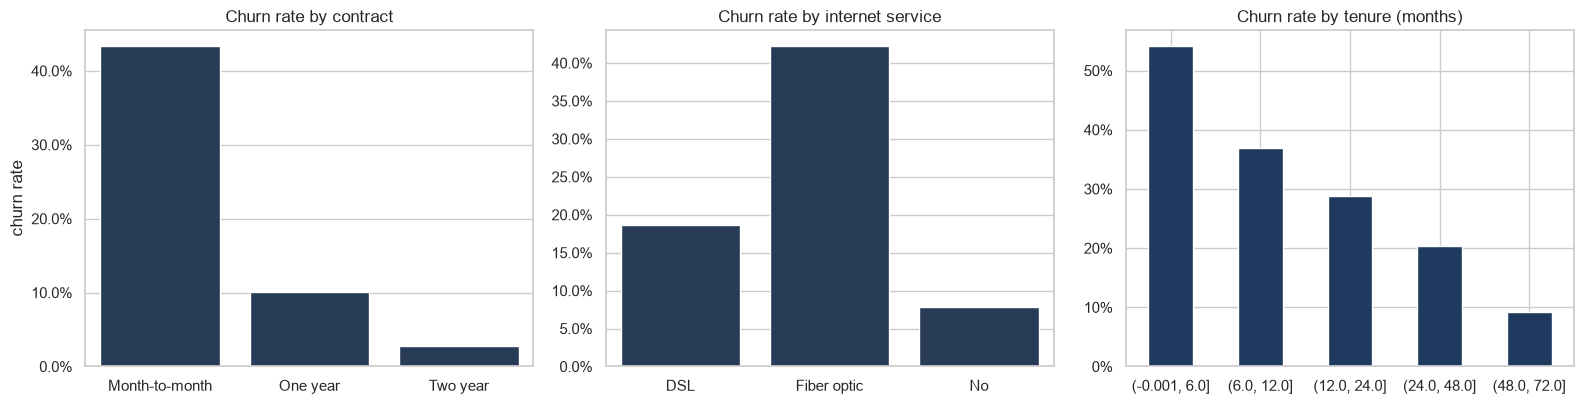

Churn,No,Yes
Contract,,
Month-to-month,0.567,0.433
One year,0.899,0.101
Two year,0.972,0.028


In [6]:
df["churn"] = df["Churn"].eq("Yes").astype(int)
print(f"churn rate: {df['churn'].mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
order = ["Month-to-month", "One year", "Two year"]
sns.barplot(data=df, x="Contract", y="churn", order=order, ax=axes[0], color="#1f3a5f", errorbar=None)
axes[0].set(title="Churn rate by contract", ylabel="churn rate", xlabel="")
sns.barplot(data=df, x="InternetService", y="churn", order=["DSL", "Fiber optic", "No"], ax=axes[1], color="#1f3a5f", errorbar=None)
axes[1].set(title="Churn rate by internet service", ylabel="", xlabel="")
bins = pd.cut(df["tenure"], [0, 6, 12, 24, 48, 72], include_lowest=True)
df.groupby(bins, observed=True)["churn"].mean().plot.bar(ax=axes[2], color="#1f3a5f", rot=0)
axes[2].set(title="Churn rate by tenure (months)", ylabel="", xlabel="")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
plt.tight_layout()
plt.savefig(FIG / "churn_drivers.png", dpi=150, bbox_inches="tight")
plt.show()

pd.crosstab(df["Contract"], df["Churn"], normalize="index")

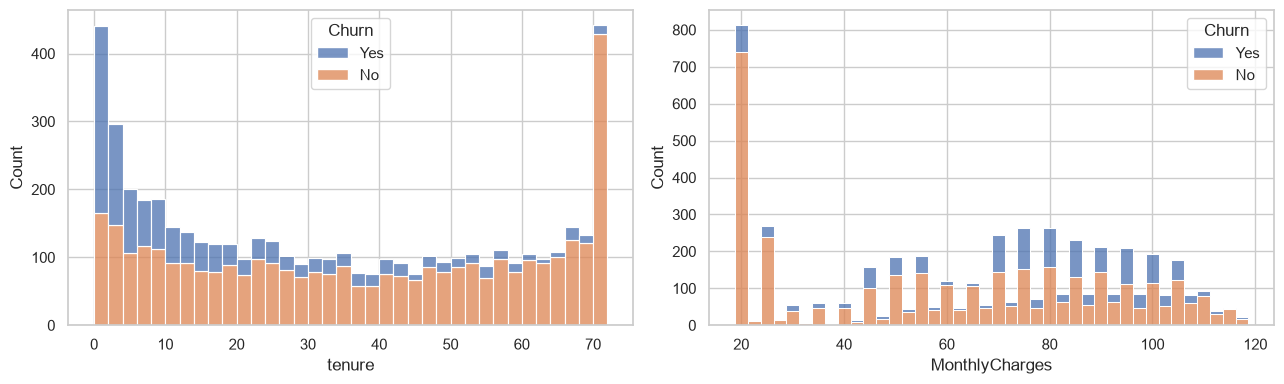

tenure vs MonthlyCharges correlation: 0.24


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=36, multiple="stack", ax=axes[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=40, multiple="stack", ax=axes[1])
plt.tight_layout()
plt.show()
print("tenure vs MonthlyCharges correlation:", round(df["tenure"].corr(df["MonthlyCharges"]), 3))

- **Contract** is the strongest single signal: month-to-month customers churn far more than customers on one- or two-year contracts.
- **Tenure**: most churn happens in the first year, and above all in the first six months.
- **Fiber optic** customers churn more than DSL customers, even though they pay more.
- Neither numeric feature is normally distributed (tenure has spikes at both ends, and many charges sit near $20 for no-internet plans). Tree models don't mind, and the linear model gets standardised inputs. The two numeric features are only weakly correlated, so collinearity is not a concern.

## 4. Split and preprocessing

I hold out 20% of customers, stratified by churn, and don't touch them until section 8. Everything before that
(model choice, tuning, threshold) uses 5-fold cross-validation on the training 80%.

- Contract is ordinal (month → one year → two years), so it gets an ordinal code.
- The other categoricals are one-hot encoded.
- The numeric features are standardised. Trees ignore the scaling, but it matters for logistic regression and KNN.

In [8]:
X = df.drop(columns=["Churn", "churn"])
y = df["churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train {len(X_train)}  test {len(X_test)}  test churn rate {y_test.mean():.1%}")

numeric = ["tenure", "MonthlyCharges"]
nominal = ["Dependents", "PaperlessBilling", "InternetService"] + addons

def preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric),
        ("nom", OneHotEncoder(drop="first"), nominal),
        ("ord", OrdinalEncoder(categories=[order]), ["Contract"]),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

train 3944  test 986  test churn rate 26.7%


## 5. Model comparison

Seven classifiers with default settings, and a dummy that always predicts the base rate.
Each is scored with and without **Neighbourhood Cleaning Rule** undersampling, which removes majority-class
points that sit among churners. Resampling happens inside each fold only.

- F1 is computed at the default 0.5 threshold.
- PR-AUC (average precision) is threshold-free. It is the fairer comparison, because the threshold gets chosen later by cost.

In [9]:
models = {
    "Dummy (base rate)": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=SEED),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=SEED, n_jobs=4, verbosity=0),
    "LightGBM": LGBMClassifier(random_state=SEED, verbose=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
}

def pipe(model, resample):
    steps = [("prep", preprocessor())]
    if resample:
        steps.append(("ncr", NeighbourhoodCleaningRule()))
    return Pipeline(steps + [("model", model)])

rows = []
for name, model in models.items():
    for resample in (False, True):
        s = cross_validate(pipe(model, resample), X_train, y_train, cv=cv, scoring=["f1", "average_precision"], n_jobs=-1)
        rows.append({"model": name, "NCR": resample,
                     "F1@0.5": s["test_f1"].mean(), "F1 std": s["test_f1"].std(),
                     "PR-AUC": s["test_average_precision"].mean(), "PR-AUC std": s["test_average_precision"].std()})
comparison = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
comparison

,model,NCR,F1@0.5,F1 std,PR-AUC,PR-AUC std
0,Logistic Regression,False,0.575,0.023,0.654,2.790e-02
1,Logistic Regression,True,0.622,0.016,0.651,2.788e-02
2,Gradient Boosting,True,0.620,0.014,0.647,3.390e-02
3,Gradient Boosting,False,0.580,0.031,0.643,3.153e-02
4,LightGBM,False,0.564,0.032,0.626,4.392e-02
5,LightGBM,True,0.616,0.015,0.621,3.715e-02
6,XGBoost,True,0.604,0.017,0.607,3.184e-02
7,Random Forest,True,0.614,0.011,0.603,2.367e-02
8,XGBoost,False,0.547,0.027,0.600,4.310e-02
9,Random Forest,False,0.529,0.024,0.595,3.041e-02


- Undersampling with NCR raises F1 at 0.5 for every model, but it barely changes PR-AUC. It mostly moves predictions
  across the 0.5 line rather than improving the ranking. Since the threshold is tuned by cost later, that effect doesn't matter here.
- **Plain logistic regression is the best model, or tied for best** (PR-AUC 0.654 against 0.643–0.647 for gradient
  boosting). The gaps are smaller than one standard deviation, which makes sense with ten mostly categorical features.
- I tune gradient boosting next to see whether tuning closes the gap. Logistic regression goes forward as the
  simpler rival.

## 6. Tuning gradient boosting

The grid is small on purpose, and it optimises PR-AUC rather than F1, because the threshold comes later.

In [10]:
grid = GridSearchCV(
    pipe(GradientBoostingClassifier(random_state=SEED), resample=True),
    param_grid={
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__n_estimators": [100, 300],
        "model__max_depth": [2, 3],
        "model__subsample": [0.5, 1.0],
    },
    scoring="average_precision", cv=cv, n_jobs=-1,
)
grid.fit(X_train, y_train)
res = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
print("best params:", grid.best_params_)
res[["params", "mean_test_score", "std_test_score"]].head(5)

best params: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 300, 'model__subsample': 1.0}


,params,mean_test_score,std_test_score
11,"{'model__learning_rate': 0.05, 'model__max_dep...",0.661,0.030
6,"{'model__learning_rate': 0.01, 'model__max_dep...",0.658,0.030
9,"{'model__learning_rate': 0.05, 'model__max_dep...",0.658,0.027
10,"{'model__learning_rate': 0.05, 'model__max_dep...",0.658,0.028
17,"{'model__learning_rate': 0.1, 'model__max_dept...",0.657,0.028


In [11]:
lr_ap = comparison.query("model == 'Logistic Regression' and NCR")["PR-AUC"].item()
print(f"tuned GB PR-AUC {grid.best_score_:.3f}  vs  logistic regression {lr_ap:.3f}")

tuned GB PR-AUC 0.661  vs  logistic regression 0.651


## 7. Choosing the threshold by cost

A missed churner costs ten times as much as an unneeded offer (100% vs 10% of the monthly charge), so 0.5 is
the wrong cut-off. I take out-of-fold churn probabilities on the training set, compute the cost of every
threshold from 0.01 to 0.99, and keep the cheapest one. The test set is still untouched at this point.

Logistic Regression         cost-optimal threshold 0.06   out-of-fold cost/customer $5.43


Gradient Boosting (tuned)   cost-optimal threshold 0.09   out-of-fold cost/customer $5.44
picked: Logistic Regression


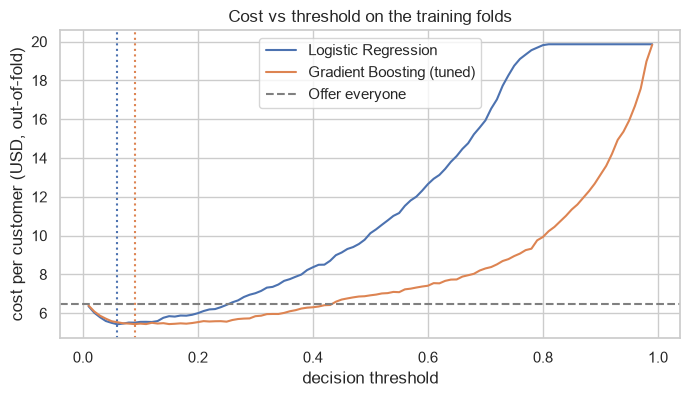

In [12]:
def strategy_cost(offer, churned, charges, discount=DISCOUNT, success=SUCCESS_RATE):
    # One-month revenue lost under a targeting decision.
    offer, churned = np.asarray(offer, bool), np.asarray(churned, bool)
    charges = np.asarray(charges, float)
    discount_paid = discount * charges[offer & ~churned].sum() + success * discount * charges[offer & churned].sum()
    lost = charges[~offer & churned].sum() + (1 - success) * charges[offer & churned].sum()
    return discount_paid + lost

thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)
candidates = {
    "Logistic Regression": pipe(LogisticRegression(max_iter=1000), resample=False),
    "Gradient Boosting (tuned)": grid.best_estimator_,
}
chosen, curves = {}, {}
for name, est in candidates.items():
    oof = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
    costs = np.array([strategy_cost(oof >= t, y_train, X_train["MonthlyCharges"]) for t in thresholds])
    curves[name] = costs / len(X_train)
    chosen[name] = thresholds[costs.argmin()]
    print(f"{name:27s} cost-optimal threshold {chosen[name]:.2f}   out-of-fold cost/customer ${curves[name].min():.2f}")

# the model to ship is picked here, on the training folds, before the test set is scored
best_name = min(curves, key=lambda n: curves[n].min())
print("picked:", best_name)

fig, ax = plt.subplots(figsize=(8, 4))
for name, c in curves.items():
    ax.plot(thresholds, c, label=name)
    ax.axvline(chosen[name], ls=":", color=ax.lines[-1].get_color())
ax.axhline(DISCOUNT * X_train["MonthlyCharges"].mean(), color="grey", ls="--", label="Offer everyone")
ax.set(xlabel="decision threshold", ylabel="cost per customer (USD, out-of-fold)", title="Cost vs threshold on the training folds")
ax.legend()
plt.show()

## 8. Test set: every strategy on the same 986 customers

Each strategy is scored on the held-out customers, using the thresholds fixed in section 7.

In [13]:
charges_test = X_test["MonthlyCharges"].to_numpy()
fitted = {name: est.fit(X_train, y_train) for name, est in candidates.items()}
proba = {name: est.predict_proba(X_test)[:, 1] for name, est in fitted.items()}

strategies = {
    "Offer nobody": np.zeros(len(X_test), bool),
    "Offer everyone": np.ones(len(X_test), bool),
    "Rule: month-to-month contract": (X_test["Contract"] == "Month-to-month").to_numpy(),
    "Gradient Boosting @ 0.50": proba["Gradient Boosting (tuned)"] >= 0.5,
    f"Logistic Regression @ {chosen['Logistic Regression']:.2f}": proba["Logistic Regression"] >= chosen["Logistic Regression"],
    f"Gradient Boosting @ {chosen['Gradient Boosting (tuned)']:.2f}": proba["Gradient Boosting (tuned)"] >= chosen["Gradient Boosting (tuned)"],
}
rows = []
for name, offer in strategies.items():
    rows.append({
        "strategy": name,
        "offered": int(offer.sum()),
        "recall": recall_score(y_test, offer, zero_division=0),
        "precision": precision_score(y_test, offer, zero_division=0),
        "cost (USD)": strategy_cost(offer, y_test, charges_test),
    })
results = pd.DataFrame(rows)
blanket = results.loc[results.strategy == "Offer everyone", "cost (USD)"].item()
results["vs offer everyone"] = results["cost (USD)"] / blanket - 1
results.style.format({"recall": "{:.1%}", "precision": "{:.1%}", "cost (USD)": "${:,.0f}", "vs offer everyone": "{:+.1%}"})

,strategy,offered,recall,precision,cost (USD),vs offer everyone
0,Offer nobody,0,0.0%,0.0%,"$19,654",+205.2%
1,Offer everyone,986,100.0%,26.7%,"$6,439",+0.0%
2,Rule: month-to-month contract,544,92.0%,44.5%,"$5,538",-14.0%
3,Gradient Boosting @ 0.50,398,81.0%,53.5%,"$6,244",-3.0%
4,Logistic Regression @ 0.06,700,97.7%,36.7%,"$5,259",-18.3%
5,Gradient Boosting @ 0.09,643,97.0%,39.7%,"$5,226",-18.8%


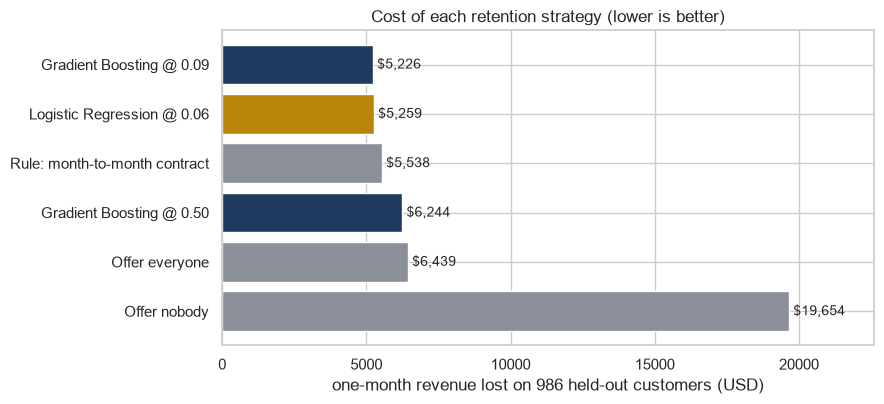

In [14]:
plot = results.sort_values("cost (USD)")
best = f"{best_name} @ {chosen[best_name]:.2f}"
colors = ["#b8860b" if s == best else ("#8a8f98" if s.startswith(("Offer", "Rule")) else "#1f3a5f") for s in plot["strategy"]]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(plot["strategy"], plot["cost (USD)"], color=colors)
for i, v in enumerate(plot["cost (USD)"]):
    ax.text(v + 150, i, f"${v:,.0f}", va="center", fontsize=10)
ax.invert_yaxis()
ax.set(xlabel="one-month revenue lost on 986 held-out customers (USD)", title="Cost of each retention strategy (lower is better)")
ax.set_xlim(0, plot["cost (USD)"].max() * 1.15)
plt.tight_layout()
plt.savefig(FIG / "cost_vs_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
offer = proba[best_name] >= chosen[best_name]
print(best_name, "at", chosen[best_name])
print(pd.DataFrame(confusion_matrix(y_test, offer), index=["stayed", "churned"], columns=["no offer", "offer"]))

Logistic Regression at 0.06
         no offer  offer
stayed        280    443
churned         6    257


- **Offer nobody** costs $19,654. That is the size of the problem.
- **Offer everyone** costs $6,439 and is the baseline to beat.
- **The contract rule** already saves 14%. It reaches 92% of churners by offering to only 55% of customers.
- **Logistic regression at 0.06**, the model picked on the training folds, costs **$5,259: 18.3% below offering everyone
  and 5.0% below the rule.** It misses 6 of 263 churners and makes 443 unneeded offers.
- Tuned gradient boosting at 0.09 ends up at $5,226, but it was a tie on the training folds ($5.44 vs $5.43 per
  customer). Picking it because it wins on the test set would be test-set selection, so I report logistic regression.
  The simpler model is also easier to explain to a retention team.
- **The default threshold is the expensive mistake.** Gradient boosting at 0.5 has the best F1-style balance, yet it is
  barely better than offering everyone (−3%) and worse than the rule. A missed churner costs ten times as much as an
  unneeded offer, so the best threshold is low.

For comparison, the first version of this analysis reported a 2.74× saving. It was an error: it compared the blanket cost on the
*training* set with the model's cost on the *test* set, and it counted lost customers twice while leaving out the discount.

### Sensitivity: what if fewer churners accept the offer?

The default assumes every offered churner stays. Here I lower that success rate and recompute every strategy.
The thresholds stay as chosen above.

In [16]:
rows = []
for s in [1.0, 0.75, 0.5, 0.25]:
    row = {"success rate": f"{s:.0%}"}
    for name, offer in strategies.items():
        row[name] = strategy_cost(offer, y_test, charges_test, success=s)
    rows.append(row)
sens = pd.DataFrame(rows).set_index("success rate")
sens.style.format("${:,.0f}").highlight_min(axis=1, color="#f3e3b3")

,Offer nobody,Offer everyone,Rule: month-to-month contract,Gradient Boosting @ 0.50,Logistic Regression @ 0.06,Gradient Boosting @ 0.09
success rate,,,,,,
100%,"$19,654","$6,439","$5,538","$6,244","$5,259","$5,226"
75%,"$19,654","$10,861","$9,546","$9,937","$9,599","$9,531"
50%,"$19,654","$15,283","$13,553","$13,630","$13,939","$13,836"
25%,"$19,654","$19,705","$17,561","$17,322","$18,279","$18,141"


The model's advantage depends on the offer working:

- At **100%** success, the cost-thresholded models are the cheapest option.
- At **75%**, the contract rule already matches them.
- At **50% or below**, the rule and the untuned 0.5 threshold both beat the low-threshold models. When most offers fail,
  sending fewer of them is better.

So the most valuable next step is not a better classifier but **measuring the success rate** with a small holdout
trial. The best threshold should then be recomputed at that rate.

## 9. What the model relies on

I use permutation importance on the test set, measured as the drop in PR-AUC when one raw column is shuffled,
plus partial dependence for the two numeric features.

tenure              0.186
Contract            0.100
InternetService     0.084
MonthlyCharges      0.044
OnlineSecurity      0.016
OnlineBackup        0.013
PaperlessBilling    0.012
TechSupport         0.009
DeviceProtection    0.003
Dependents          0.003
dtype: float64


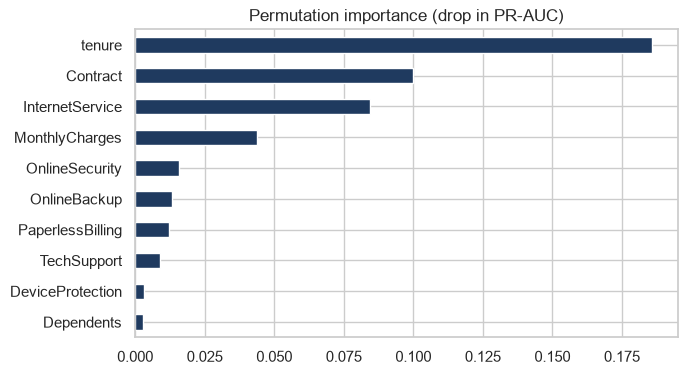

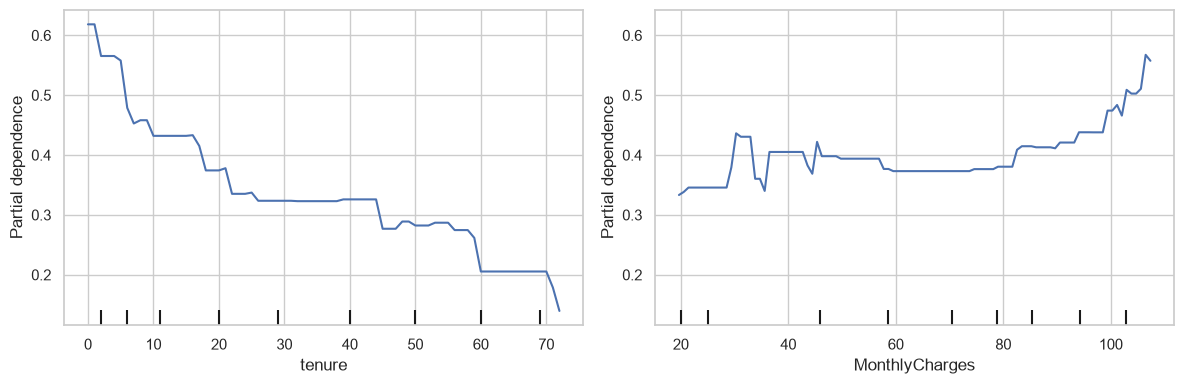

In [17]:
gb = fitted["Gradient Boosting (tuned)"]
pi = permutation_importance(gb, X_test, y_test, scoring="average_precision", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
print(imp.sort_values(ascending=False).round(3))
imp.plot.barh(figsize=(7, 4), color="#1f3a5f", title="Permutation importance (drop in PR-AUC)")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(gb, X_train.astype({"tenure": float}), ["tenure", "MonthlyCharges"], ax=ax)
plt.tight_layout()
plt.show()

- **Tenure** matters most. 58% of customers in their first three months churn, compared with 9% after four years.
- **Contract** comes next. It is the same signal that makes the one-line rule so strong.
- **Internet service** (fiber) and **monthly charges** follow. Customers on the ~$20 no-internet plans rarely churn (10%), and bills above $70 churn most (33–38%). The relationship is not a straight line, because price is tangled up with service type.
- The add-ons (security, backup, tech support) and dependents add little on top.

In practice: target new, month-to-month, high-bill customers, and treat the 6% threshold as a starting point to
re-tune once the offer's real success rate is known.

## 10. Limitations and next steps

- **One month is a short horizon.** A lost customer costs more than one bill, so the real value of catching churners is higher than shown here. Using customer lifetime value would push the best threshold lower and widen the model's margin.
- **The success rate is assumed, not measured.** A small randomised trial (offer vs. no offer among flagged customers) would measure it, and would show whether the offer causes customers to stay or just goes to people who would have stayed anyway (uplift).
- **Only ten features.** There is no usage, support-ticket or payment history, so there is little signal beyond contract, tenure and price.
- **A static snapshot.** A production version would score customers monthly and track whether its cost advantage holds over time.